In [2]:
#initialization
import matplotlib.pyplot as plt
import numpy as np
import math

# importing Qiskit
from qiskit import IBMQ, Aer, transpile, execute
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.providers.ibmq import least_busy

# import basic plot tools
from qiskit.visualization import plot_histogram

In [107]:
n = 2
grover_circuit = QuantumCircuit(n)

In [108]:
def initialize_s(qc, qubits):
    """Apply a H-gate to 'qubits' in qc"""
    for q in qubits:
        qc.h(q)
    return qc


In [117]:
def oracle(qc):
    qc.x(1)  # Flip qubit 1 instead of qubit 0
    qc.cz(1,0)  # Swap control and target
    qc.x(1)  # Undo the flip on qubit 1
    return qc
    
def diffuser(qc):    
    qc.h([0,1])
    qc.x([0,1])
    qc.cz(0,1)
    qc.x([0,1])
    qc.h([0,1])
    return qc.to_instruction()

def grover_experiment():
    qc = QuantumCircuit(2, 2)

    # Step 1: Apply Hadamard to create uniform superposition
    qc.h([0,1])

    oracle(qc)
    diffuser(qc)
    
    return qc

grover_circuit = grover_experiment()

sv_sim = Aer.get_backend('statevector_simulator')
result = sv_sim.run(grover_circuit).result()
statevec = result.get_statevector()
from qiskit.visualization import array_to_latex
array_to_latex(statevec, prefix="|\\psi\\rangle =")


<IPython.core.display.Latex object>

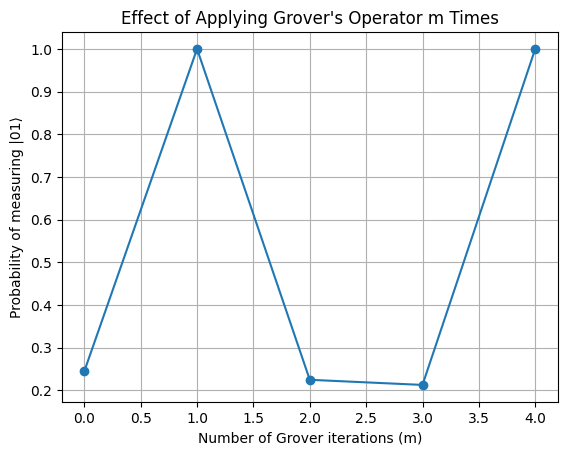

In [1]:
from qiskit import QuantumCircuit, Aer, execute
from qiskit import Aer, execute
import matplotlib.pyplot as plt

# Define the Oracle as an Instruction
def oracle():
    qc = QuantumCircuit(2, name="Oracle")
    qc.x(1)            # Flip qubit 1 instead of qubit 0
    qc.cz(1, 0)        # Swap control and target
    qc.x(1)            # Undo the flip on qubit 1
    return qc.to_instruction()  # Convert to gate instruction

# Define the Diffuser as an Instruction
def diffuser():
    qc = QuantumCircuit(2, name="Diffuser")
    qc.h([0, 1])
    qc.x([0, 1])
    qc.cz(0, 1)
    qc.x([0, 1])
    qc.h([0, 1])
    return qc.to_instruction()  # Convert to gate instruction

# Function to apply Grover's operator 'm' times and measure
def grover_experiment(m):
    qc = QuantumCircuit(2, 2)

    # Step 1: Apply Hadamard to create uniform superposition
    qc.h([0, 1])

    # Get the oracle and diffuser as gates
    oracle_gate = oracle()
    diffuser_gate = diffuser()

    # Step 2: Apply Grover's operator 'm' times
    for _ in range(m):
        qc.append(oracle_gate, [0, 1])   # Apply Oracle
        qc.append(diffuser_gate, [0, 1])  # Apply Diffuser

    # Step 3: Measure
    qc.measure([0, 1], [0, 1])

    return qc  # Return the quantum circuit

# Simulate the experiment for different values of m
def run_experiment():
    sim = Aer.get_backend('aer_simulator')
    m_values = range(0, 5)  # Test for m = 0 to 4 iterations of Grover's operator
    probabilities = []

    for m in m_values:
        qc = grover_experiment(m)
        
        # Execute the circuit with a sufficient number of shots (e.g., 1000)
        result = execute(qc, sim, shots=1000).result()
        counts = result.get_counts()
        
        # Get the probability of measuring |01⟩
        probability_01 = counts.get('01', 0) / 1000
        probabilities.append(probability_01)

    # Plot the probability of measuring |01⟩ for each m
    plt.plot(m_values, probabilities, marker='o')
    plt.xlabel('Number of Grover iterations (m)')
    plt.ylabel('Probability of measuring |01⟩')
    plt.title('Effect of Applying Grover\'s Operator m Times')
    plt.grid(True)
    plt.show()

# Run the experiment
run_experiment()





In [110]:
# Diffusion operator (U_s)
grover_circuit.h([0,1])
grover_circuit.x([0,1])
grover_circuit.cz(0,1)
grover_circuit.x([0,1])
grover_circuit.h([0,1])
grover_circuit.draw()

┌───┐        ┌───┐┌───┐        ┌───┐┌───┐
q_0: ┤ H ├──────■─┤ H ├┤ X ├──────■─┤ X ├┤ H ├
     ├───┤┌───┐ │ ├───┤├───┤┌───┐ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘└───┘   └───┘└───┘

In [111]:
sv_sim = Aer.get_backend('statevector_simulator')
result = sv_sim.run(grover_circuit).result()
statevec = result.get_statevector()
from qiskit.visualization import array_to_latex
array_to_latex(statevec, prefix="|\\psi\\rangle =")

<IPython.core.display.Latex object>

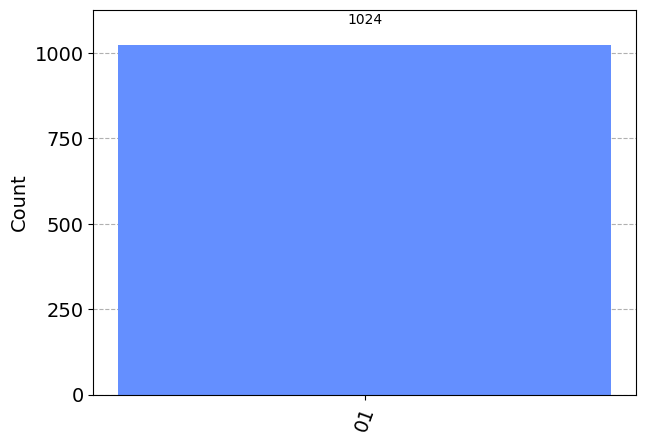

In [112]:
grover_circuit.measure_all()

qasm_sim = Aer.get_backend('qasm_simulator')
result = qasm_sim.run(grover_circuit).result()
counts = result.get_counts()
plot_histogram(counts)

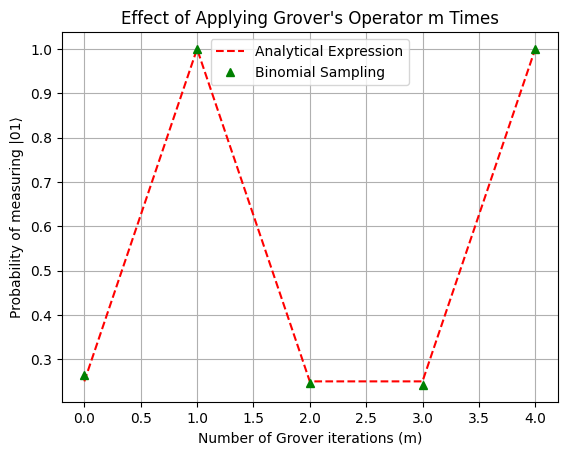

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# Compute the analytical probability based on sin²((2m+1)θ)
def analytical_probability(m, a):
    theta = np.arcsin(np.sqrt(a))
    return np.sin((2 * m + 1) * theta) ** 2

# Perform binomial sampling on the analytical probability
def binomial_sampling(m_values, a, shots=1000):
    probabilities_analytical = []
    probabilities_binomial = []

    for m in m_values:
        # Get the theoretical probability from the formula
        prob_analytical = analytical_probability(m, a)
        probabilities_analytical.append(prob_analytical)

        # Apply binomial sampling (simulate 1000 shots)
        binomial_sample = binom.rvs(n=shots, p=prob_analytical) / shots
        probabilities_binomial.append(binomial_sample)

    return probabilities_analytical, probabilities_binomial

# Run the experiment with binomial sampling
def run_experiment():
    m_values = range(0, 5)  # Test for m = 0 to 4 iterations
    a = 1 / 4  # Initial amplitude for state |01⟩
    
    probabilities_analytical, probabilities_binomial = binomial_sampling(m_values, a)

    # Plot results
    plt.plot(m_values, probabilities_analytical, 'r--', label="Analytical Expression")
    plt.plot(m_values, probabilities_binomial, 'g^', label="Binomial Sampling")

    plt.xlabel('Number of Grover iterations (m)')
    plt.ylabel('Probability of measuring |01⟩')
    plt.title('Effect of Applying Grover\'s Operator m Times')
    plt.legend()
    plt.grid(True)
    plt.show()

# Run the experiment
run_experiment()


In [17]:
import numpy as np
import random
from qiskit import QuantumCircuit
from qiskit.circuit.library import XGate, MCXGate

def generalized_grover_operator(A_circuit, n, k):
    """
    Creates the generalized Grover operator G = D_A O.
    
    Parameters:
    - A_circuit: QuantumCircuit, the initialization operator (state preparation circuit).
    - n: int, number of qubits (defines the search space size N = 2^n).
    - k: int, number of marked "good" states (must be < 2^n).
    
    Returns:
    - QuantumCircuit: The Grover operator circuit (Oracle + Diffuser).
    """

    N = 2**n  # Total number of states
    assert k < N, "Number of good states must be less than total states"

    # Step 1: Randomly select 'k' good states
    all_states = list(range(N))
    good_states = random.sample(all_states, k)  # Randomly select k marked states

    # Step 2: Construct the Oracle O
    oracle = QuantumCircuit(n, name="Oracle")

    for state in good_states:
        state_bin = format(state, f'0{n}b')  # Convert to binary string
        print(f"Processing state: {state_bin}")  # Debug: Print the binary representation of the state
    
        # Apply X-gates for each '0' bit
        for qubit, bit in enumerate(state_bin):
            if bit == '0':  # Apply X-gate to flip 0 to 1
                print(f"Applying X-gate to qubit {qubit}")  # Debug: Print when applying X
                oracle.x(qubit)

        # Apply multi-controlled Z (MCX + H)
        oracle.append(MCXGate(n - 1), list(range(n - 1)) + [n - 1])
        oracle.h(n - 1)
        oracle.mcx(list(range(n - 1)), n - 1)
        oracle.h(n - 1)

        # Uncompute X-gates (restore original state)
        for qubit, bit in enumerate(state_bin):
            if bit == '0':
                print(f"Uncomputing X-gate on qubit {qubit}")  # Debug: Print when uncomputing X
                oracle.x(qubit)

    oracle = oracle.to_instruction()  # Convert to gate


    # Construct the diffusion operator
    diffuser = QuantumCircuit(n)
    diffuser.h(range(n))
    diffuser.x(range(n))
    diffuser.h(n - 1)
    diffuser.mcx(list(range(n - 1)), n - 1)
    diffuser.h(n - 1)
    diffuser.x(range(n))
    diffuser.h(range(n))

    # Apply A again
    diffuser.append(A_circuit, range(n))
    diffuser = diffuser.to_instruction()

    # Step 4: Combine Oracle and Diffuser into the Grover Operator
    grover_operator = QuantumCircuit(n, name="Grover")
    grover_operator.append(oracle, range(n))
    grover_operator.append(diffuser, range(n))

    return grover_operator, good_states



Processing state: 011
Applying X-gate to qubit 0
Uncomputing X-gate on qubit 0
Processing state: 100
Applying X-gate to qubit 1
Applying X-gate to qubit 2
Uncomputing X-gate on qubit 1
Uncomputing X-gate on qubit 2
Good States: [3, 4]
Observed counts: {'001': 43, '110': 34, '100': 32, '010': 31, '000': 311, '101': 280, '011': 38, '111': 255}


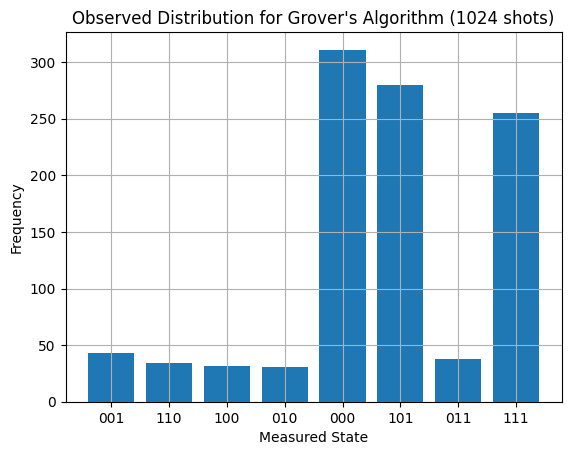

In [41]:

# Create an example initialization operator (A_circuit)
def example_initialization_circuit(n):
    A_circuit = QuantumCircuit(n, name="Initialization")
    
    # Create a uniform superposition state (Hadamard on all qubits)
    A_circuit.h(range(n))
    
    return A_circuit

# Simulate the experiment for 1024 shots
def simulate_grover(n, k, m, shots=1024):
    # Create the initialization circuit A_circuit
    A_circuit = example_initialization_circuit(n)
    
    # Get the generalized Grover operator and the good states
    grover_operator, good_states = generalized_grover_operator(A_circuit, n, k)
    
    # Step 1: Initialize quantum circuit
    qc = QuantumCircuit(n, n)
    
    # Apply the Grover operator 'm' times
    for _ in range(m):
        qc.append(grover_operator, range(n))
    
    # Step 2: Measure
    qc.measure(range(n), range(n))

    # Step 3: Simulate the circuit
    sim = Aer.get_backend('aer_simulator')
    result = execute(qc, sim, shots=shots).result()

    # Get the counts (distribution of measured states)
    counts = result.get_counts()

    # Print the good states
    print(f"Good States: {good_states}")
    print(f"Observed counts: {counts}")

    # Return the observed counts
    return counts

# Set the parameters
n = 3  # Number of qubits
k = 2  # Number of good states
m = 3  # Number of Grover iterations
shots = 1024

# Run the simulation
counts = simulate_grover(n, k, m, shots)

# Plot the results
def plot_results(counts):
    plt.bar(counts.keys(), counts.values())
    plt.xlabel('Measured State')
    plt.ylabel('Frequency')
    plt.title('Observed Distribution for Grover\'s Algorithm (1024 shots)')
    plt.grid(True)
    plt.show()

# Plot the observed distribution
plot_results(counts)



good states: [5 6]
Measurement results for m=1: {'101': 528, '011': 496}


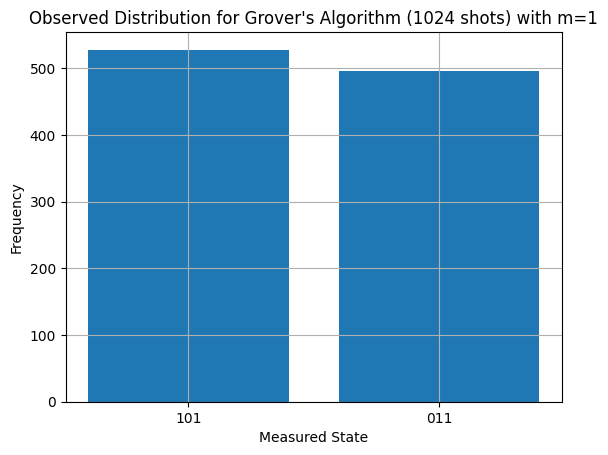

Measurement results for m=2: {'000': 251, '011': 253, '110': 268, '101': 252}


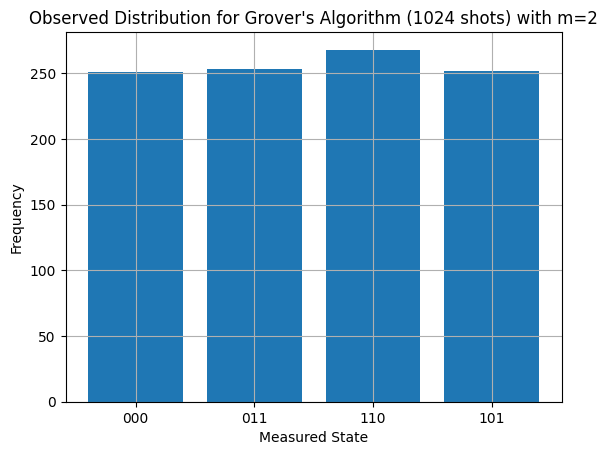

Measurement results for m=3: {'101': 111, '100': 122, '110': 128, '001': 145, '111': 131, '011': 129, '000': 140, '010': 118}


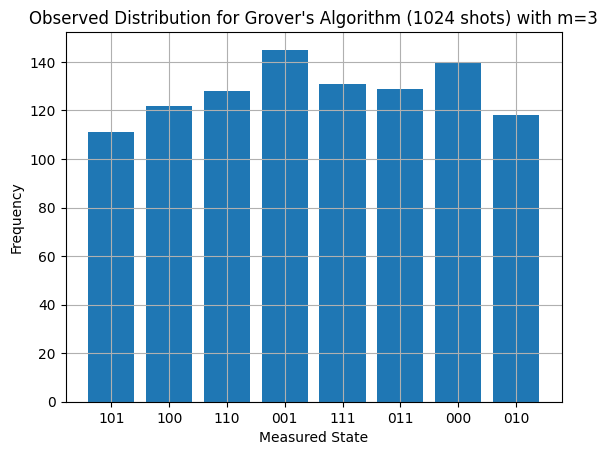

Measurement results for m=4: {'111': 261, '100': 262, '000': 255, '011': 246}


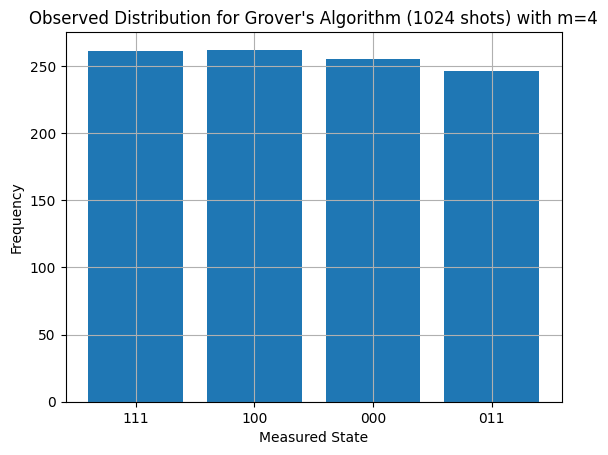

Measurement results for m=5: {'110': 117, '001': 145, '100': 146, '101': 115, '000': 112, '010': 121, '111': 140, '011': 128}


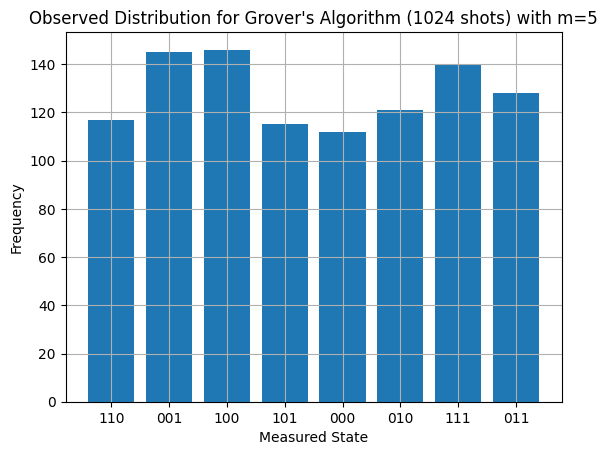

Measurement results for m=6: {'101': 72, '110': 579, '001': 54, '100': 64, '111': 56, '011': 64, '010': 67, '000': 68}


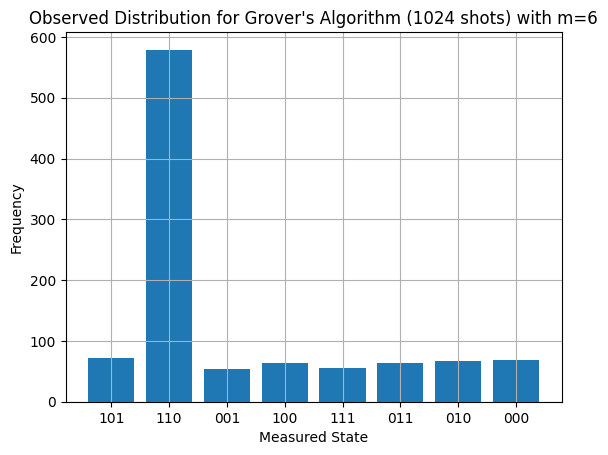

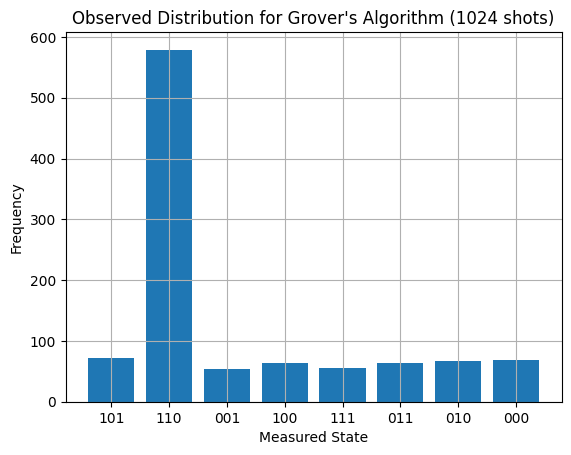

In [43]:
import numpy as np
import qiskit
from qiskit import QuantumCircuit, Aer, transpile, execute
from qiskit.circuit.library import MCXGate
from qiskit.quantum_info import Operator

def grover_operator(init_op, N, k):
    num_qubits = int(np.log2(N))
    assert 2**num_qubits == N, "N must be a power of 2"
    assert k < N, "k must be less than N"
    
    # Create a quantum circuit
    qc = QuantumCircuit(num_qubits)
    
    # Apply the initialization operator
    qc.append(init_op, list(range(num_qubits)))
    
    # Choose k good states randomly
    good_states = np.random.choice(N, k, replace=False)
    print(f'good states: {good_states}')
    
    # Construct the oracle that marks good states
    oracle = QuantumCircuit(num_qubits)
    for state in good_states:
        binary_state = format(state, f'0{num_qubits}b')
        
        # Apply X gates to flip the required qubits
        for qubit, bit in enumerate(binary_state):
            if bit == '0':
                oracle.x(qubit)
                
        # Apply multi-controlled Z (MCX + H)
        oracle.append(MCXGate(num_qubits - 1), list(range(num_qubits - 1)) + [num_qubits - 1])
        oracle.h(num_qubits - 1)
        oracle.mcx(list(range(num_qubits - 1)), num_qubits - 1)
        oracle.h(num_qubits - 1)
        
        # Undo X gates
        for qubit, bit in enumerate(binary_state):
            if bit == '0':
                oracle.x(qubit)
    
    # Construct the diffusion operator
    diffuser = QuantumCircuit(num_qubits)
    diffuser.h(range(num_qubits))
    diffuser.x(range(num_qubits))
    diffuser.h(num_qubits - 1)
    diffuser.mcx(list(range(num_qubits - 1)), num_qubits - 1)
    diffuser.h(num_qubits - 1)
    diffuser.x(range(num_qubits))
    diffuser.h(range(num_qubits))
    
    # Combine the Grover operator
    grover_op = qc.compose(oracle).compose(diffuser)
    
    return Operator(grover_op)

# Example Usage
N = 8  # Total number of states
k = 2  # Number of good states
init_op = QuantumCircuit(3)
init_op.h(range(3))  # Standard uniform superposition initialization

G = grover_operator(init_op, N, k)
#print(G)

# Simulation for multiple iterations
backend = Aer.get_backend('qasm_simulator')
m_values = [1, 2, 3, 4, 5, 6]  # Different values of m to test
results = {}

for m in m_values:
    circuit = QuantumCircuit(3)
    for _ in range(m):
        circuit.append(G, range(3))
    circuit.measure_all()
    compiled_circuit = transpile(circuit, backend)
    result = execute(compiled_circuit, backend, shots=1024).result()
    counts = result.get_counts()
    results[m] = counts

# Print results for different m values
for m, counts in results.items():
    print(f"Measurement results for m={m}: {counts}")
    # Plot the results
    plt.bar(counts.keys(), counts.values())
    plt.xlabel('Measured State')
    plt.ylabel('Frequency')
    plt.title(f"Observed Distribution for Grover\'s Algorithm (1024 shots) with m={m}")
    plt.grid(True)
    plt.show()

# Plot the observed distribution
plot_results(counts)
